# CardioIA — Fase 4 · Parte 1: Pré-processamento e organização das imagens

**Objetivo:** preparar um conjunto de radiografias de tórax para treinar CNNs que detectam **cardiomegalia** (aumento da área cardíaca), um achado de imagem ligado a insuficiência cardíaca, hipertensão e doenças valvares.

**Dataset:** [NIH ChestX-ray14](https://www.kaggle.com/datasets/nih-chest-xrays/data), com 112.120 radiografias frontais de 30.805 pacientes e 14 rótulos extraídos dos laudos por NLP. Usamos o espelho público do Hugging Face (`alkzar90/NIH-Chest-X-ray-dataset`), que tem os mesmos arquivos do Kaggle e não exige login. Assim o notebook roda igual no Colab e em uma máquina local.

**Pipeline deste notebook**

| Etapa | O que fazemos | Por quê |
|---|---|---|
| 1. Metadados | Lemos `Data_Entry_2017_v2020.csv` | Rótulos, idade, sexo, incidência (PA/AP) e ID do paciente |
| 2. Coorte | Cardiomegalia (todas) vs. *No Finding* (amostra 2:1) | Problema binário claro e com relevância cardiológica |
| 3. Split | Treino / validação / teste = 70 / 15 / 15 **por paciente**, estratificado | Evita que o mesmo paciente apareça em treino e teste (vazamento) |
| 4. Download seletivo | Baixamos cada zip, extraímos só as imagens da coorte e apagamos o zip | 45 GB de origem viram ~200 MB processados |
| 5. Conversão de formato | PNG RGBA / escala de cinza → PNG 8 bits, 1 canal | Padroniza a entrada |
| 6. Redimensionamento | 1024×1024 → 224×224 (Lanczos) | Tamanho de entrada da ResNet50 e custo viável em CPU |
| 7. Normalização | Média e desvio calculados **só no treino** e salvos em JSON | Usados pelos modelos sem vazar informação do teste |
| 8. Verificação | Contagens, distribuições e amostras antes/depois | Documentação do pipeline |

## 0. Configuração do ambiente (Colab ou local)

In [1]:
import os, sys, io, json, time, zipfile, shutil
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # No Colab o processamento acontece no disco local da VM (mais rápido) e,
    # ao final, uma cópia compactada vai para o Google Drive para o notebook 02.
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/cardioia")
    DRIVE_DIR = Path("/content/drive/MyDrive/CardioIA-Fase4")
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
else:
    BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DRIVE_DIR = None

RAW_DIR = BASE_DIR / "data" / "nih_chestxray"        # cache temporário (zips e CSV)
OUT_DIR = BASE_DIR / "data" / "raiox_processado"     # dataset final
FIG_DIR = BASE_DIR / "docs" / "prints" / "fase4"
for p in (RAW_DIR, OUT_DIR, FIG_DIR):
    p.mkdir(parents=True, exist_ok=True)

SEED = 42
TAMANHO = 224              # lado da imagem final em pixels
RAZAO_NEG_POS = 2          # 2 exames "sem achados" para cada exame com cardiomegalia
N_ZIPS = int(os.environ.get("CARDIOIA_N_ZIPS", 12))  # 12 = dataset completo; use 1-2 para um teste rápido
HF_BASE = "https://huggingface.co/datasets/alkzar90/NIH-Chest-X-ray-dataset/resolve/main/data"

print("BASE_DIR:", BASE_DIR)
print("Zips que serão processados:", N_ZIPS, "de 12")

BASE_DIR: C:\Fiap\2TIAOR-CardioIA-Fase1-Cap1
Zips que serão processados: 12 de 12


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(SEED)

## 1. Metadados

O CSV oficial tem uma linha por imagem. Os rótulos ficam em `Finding Labels`, separados por `|`, porque uma imagem pode ter mais de um achado.

In [3]:
def baixar(url, destino, tentativas=5):
    # Download em streaming com retomada (HTTP Range) caso a conexão caia no meio.
    destino = Path(destino)
    for t in range(1, tentativas + 1):
        try:
            ja = destino.stat().st_size if destino.exists() else 0
            headers = {"Range": f"bytes={ja}-"} if ja else {}
            with requests.get(url, stream=True, headers=headers, timeout=60) as r:
                if r.status_code == 416:      # arquivo já completo
                    return destino
                r.raise_for_status()
                modo = "ab" if r.status_code == 206 else "wb"
                with open(destino, modo) as f:
                    for bloco in r.iter_content(chunk_size=1 << 20):
                        f.write(bloco)
            return destino
        except Exception as e:
            print(f"  tentativa {t} falhou: {e}")
            time.sleep(5 * t)
    raise RuntimeError(f"Falha ao baixar {url}")

csv_path = RAW_DIR / "Data_Entry_2017_v2020.csv"
if not csv_path.exists():
    baixar(f"{HF_BASE}/Data_Entry_2017_v2020.csv", csv_path)

meta = pd.read_csv(csv_path)
meta = meta.rename(columns={"Image Index": "arquivo", "Finding Labels": "achados", "Patient ID": "paciente_id",
                            "Patient Age": "idade", "Patient Gender": "sexo", "View Position": "incidencia",
                            "Follow-up #": "seguimento"})
meta = meta[["arquivo", "achados", "paciente_id", "idade", "sexo", "incidencia", "seguimento"]]
print(f"{len(meta):,} imagens de {meta.paciente_id.nunique():,} pacientes")
meta.head()

112,120 imagens de 30,805 pacientes


,arquivo,achados,paciente_id,idade,sexo,incidencia,seguimento
0,00000001_000.png,Cardiomegaly,1,57,M,PA,0
1,00000001_001.png,Cardiomegaly|Emphysema,1,58,M,PA,1
2,00000001_002.png,Cardiomegaly|Effusion,1,58,M,PA,2
3,00000002_000.png,No Finding,2,80,M,PA,0
4,00000003_001.png,Hernia,3,74,F,PA,0


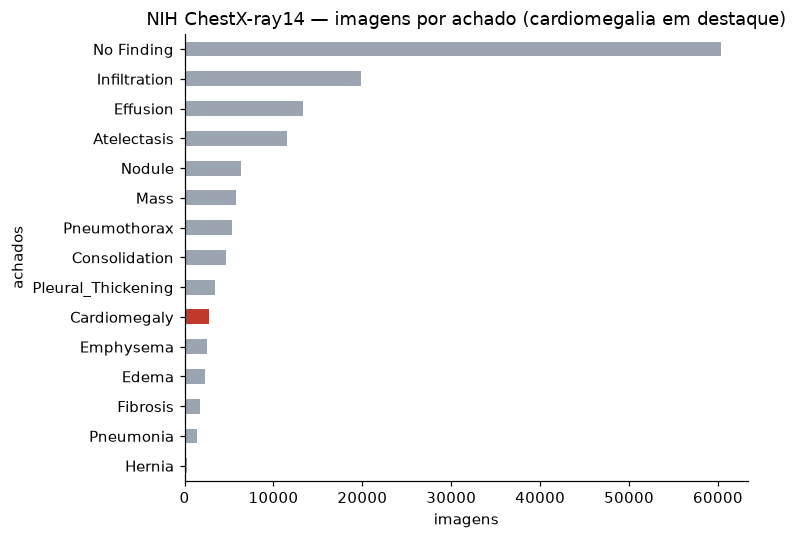

achados,No Finding,Infiltration,Effusion,Atelectasis,Nodule,Mass,Pneumothorax,Consolidation,Pleural_Thickening,Cardiomegaly,Emphysema,Edema,Fibrosis,Pneumonia,Hernia
imagens,60361,19894,13317,11559,6331,5782,5302,4667,3385,2776,2516,2303,1686,1431,227


In [4]:
# Frequência de cada achado no dataset completo
achados = meta.achados.str.split("|").explode().value_counts()
ax = achados.sort_values().plot.barh(figsize=(7, 5), color=["#c0392b" if a == "Cardiomegaly" else "#9aa5b1" for a in achados.sort_values().index])
ax.set_title("NIH ChestX-ray14 — imagens por achado (cardiomegalia em destaque)")
ax.set_xlabel("imagens")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_achados_nih.png", bbox_inches="tight"); plt.show()
achados.to_frame("imagens").T

## 2. Definição da coorte

* **Classe positiva — `cardiomegalia`:** toda imagem cujo laudo cita *Cardiomegaly*, sozinha ou junto com outros achados. São 2.776 imagens.
* **Classe negativa — `normal`:** amostra aleatória de imagens com *No Finding*, na proporção de 2 negativas para cada positiva.

Mantivemos um desbalanceamento moderado (1:2) em vez de forçar 1:1. Na prática clínica a cardiomegalia é minoritária, e queremos que as métricas reflitam isso. No treino o desbalanceamento é compensado com pesos de classe (notebook 02).

In [5]:
pos = meta[meta.achados.str.contains("Cardiomegaly")].assign(rotulo="cardiomegalia")
neg_total = meta[meta.achados == "No Finding"]
neg = neg_total.sample(n=RAZAO_NEG_POS * len(pos), random_state=SEED).assign(rotulo="normal")
coorte = pd.concat([pos, neg], ignore_index=True)
coorte["y"] = (coorte.rotulo == "cardiomegalia").astype(int)

print(f"Positivas (cardiomegalia): {len(pos):,} imagens de {pos.paciente_id.nunique():,} pacientes")
print(f"Negativas (normal):        {len(neg):,} imagens de {neg.paciente_id.nunique():,} pacientes (de {len(neg_total):,} disponíveis)")
print(f"Coorte total:              {len(coorte):,} imagens")

Positivas (cardiomegalia): 2,776 imagens de 1,566 pacientes
Negativas (normal):        5,552 imagens de 4,479 pacientes (de 60,361 disponíveis)
Coorte total:              8,328 imagens


## 3. Divisão treino / validação / teste por paciente

No NIH um mesmo paciente pode ter dezenas de exames de acompanhamento. Se dividíssemos por imagem, radiografias quase idênticas da mesma pessoa poderiam cair em treino e em teste, e a métrica sairia otimista. Por isso usamos `StratifiedGroupKFold`: **o paciente é o grupo** e a estratificação mantém a proporção de cardiomegalia parecida nos três conjuntos.

Dividimos em 20 dobras: 3 vão para teste (15%), 3 para validação (15%) e 14 para treino (70%).

In [6]:
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
coorte["split"] = "treino"
for i, (_, idx) in enumerate(sgkf.split(coorte, coorte.y, groups=coorte.paciente_id)):
    if i < 3:
        coorte.loc[idx, "split"] = "teste"
    elif i < 6:
        coorte.loc[idx, "split"] = "validacao"

# Checagem de vazamento: nenhum paciente pode aparecer em mais de um conjunto
pac_por_split = coorte.groupby("paciente_id").split.nunique()
assert (pac_por_split == 1).all(), "Paciente em mais de um conjunto!"

resumo = coorte.groupby(["split", "rotulo"]).size().unstack().loc[["treino", "validacao", "teste"]]
resumo["total"] = resumo.sum(axis=1)
resumo["% cardiomegalia"] = (100 * resumo.cardiomegalia / resumo.total).round(1)
resumo["% do total"] = (100 * resumo.total / resumo.total.sum()).round(1)
resumo["pacientes"] = coorte.groupby("split").paciente_id.nunique()
print("Nenhum paciente aparece em mais de um conjunto.")
resumo

Nenhum paciente aparece em mais de um conjunto.


rotulo,cardiomegalia,normal,total,% cardiomegalia,% do total,pacientes
split,,,,,,
treino,1943,3887,5830,33.3,70.0,3965
validacao,417,833,1250,33.4,15.0,868
teste,416,832,1248,33.3,15.0,842


## 4–6. Download seletivo, conversão de formato e redimensionamento

As imagens estão em 12 arquivos zip de 2 a 4 GB. Para cada zip:

1. baixamos o arquivo, com retomada caso a conexão caia;
2. lemos só as imagens da coorte, direto da memória;
3. **convertemos** para escala de cinza de 8 bits com 1 canal (`mode "L"`). Algumas imagens do NIH vêm em RGBA;
4. **redimensionamos** de 1024×1024 para 224×224 com filtro Lanczos, que preserva melhor bordas finas como o contorno do coração;
5. salvamos como PNG em `raiox_processado/<split>/<classe>/`, a estrutura que o Keras lê diretamente;
6. apagamos o zip para liberar espaço.

A etapa é idempotente: zips já processados ficam registrados e são pulados se o notebook for rodado de novo.

In [7]:
for split in ("treino", "validacao", "teste"):
    for classe in ("cardiomegalia", "normal"):
        (OUT_DIR / split / classe).mkdir(parents=True, exist_ok=True)

alvo = coorte.set_index("arquivo")[["split", "rotulo"]].to_dict("index")
log_path = RAW_DIR / "zips_processados.json"
feitos = set(json.loads(log_path.read_text())) if log_path.exists() else set()
modos_originais, tamanhos_originais = {}, {}
exemplos_originais = {}   # guardamos 4 originais para a figura "antes/depois"

def processar_imagem(dados, nome):
    img = Image.open(io.BytesIO(dados))
    modos_originais[img.mode] = modos_originais.get(img.mode, 0) + 1
    tamanhos_originais[img.size] = tamanhos_originais.get(img.size, 0) + 1
    if len(exemplos_originais) < 4 and nome not in exemplos_originais and alvo[nome]["split"] == "treino":
        if (alvo[nome]["rotulo"] == "cardiomegalia") == (len(exemplos_originais) % 2 == 0):
            exemplos_originais[nome] = img.convert("L").copy()
    img = img.convert("L")                                            # conversão de formato
    img = img.resize((TAMANHO, TAMANHO), Image.Resampling.LANCZOS)   # redimensionamento
    info = alvo[nome]
    img.save(OUT_DIR / info["split"] / info["rotulo"] / nome, optimize=True)

inicio = time.time()
for n in range(1, N_ZIPS + 1):
    nome_zip = f"images_{n:03d}.zip"
    if nome_zip in feitos:
        print(f"{nome_zip}: já processado, pulando")
        continue
    t0 = time.time()
    zpath = baixar(f"{HF_BASE}/images/{nome_zip}", RAW_DIR / nome_zip)
    t_down = time.time() - t0
    selecionadas = 0
    with zipfile.ZipFile(zpath) as z:
        for membro in z.namelist():
            nome = Path(membro).name
            if nome in alvo:
                processar_imagem(z.read(membro), nome)
                selecionadas += 1
    zpath.unlink()
    feitos.add(nome_zip)
    log_path.write_text(json.dumps(sorted(feitos)))
    print(f"{nome_zip}: download {t_down/60:.1f} min · {selecionadas} imagens da coorte processadas")

print(f"\nTempo total: {(time.time() - inicio)/60:.1f} min")
print("Modos de cor encontrados nas originais:", modos_originais)
print("Tamanhos originais:", {f"{w}x{h}": c for (w, h), c in tamanhos_originais.items()})

images_001.zip: download 1.0 min · 442 imagens da coorte processadas


images_002.zip: download 1.7 min · 761 imagens da coorte processadas


images_003.zip: download 1.8 min · 997 imagens da coorte processadas


images_004.zip: download 2.0 min · 664 imagens da coorte processadas


images_005.zip: download 1.9 min · 728 imagens da coorte processadas


images_006.zip: download 2.0 min · 759 imagens da coorte processadas


... (2 outputs left out)

images_009.zip: download 1.9 min · 666 imagens da coorte processadas


images_010.zip: download 1.9 min · 723 imagens da coorte processadas


images_011.zip: download 1.9 min · 611 imagens da coorte processadas


images_012.zip: download 1.1 min · 566 imagens da coorte processadas

Tempo total: 28.1 min
Modos de cor encontrados nas originais: {'L': 8296, 'RGBA': 32}
Tamanhos originais: {'1024x1024': 8328}


In [8]:
# Reconcilia o índice com o que foi de fato salvo (útil quando N_ZIPS < 12)
coorte["caminho"] = coorte.apply(lambda r: f"{r.split}/{r.rotulo}/{r.arquivo}", axis=1)
coorte["existe"] = coorte.caminho.map(lambda c: (OUT_DIR / c).exists())
print(f"Imagens processadas: {coorte.existe.sum():,} de {len(coorte):,}")
indice = coorte[coorte.existe].drop(columns=["existe"]).reset_index(drop=True)
indice["faixa_etaria"] = pd.cut(indice.idade, bins=[0, 17, 39, 59, 120], labels=["0-17", "18-39", "40-59", "60+"])
indice.to_csv(OUT_DIR / "indice.csv", index=False)
indice.head()

Imagens processadas: 8,328 de 8,328


,arquivo,achados,paciente_id,idade,sexo,incidencia,seguimento,rotulo,y,split,caminho,faixa_etaria
0,00000001_000.png,Cardiomegaly,1,57,M,PA,0,cardiomegalia,1,treino,treino/cardiomegalia/00000001_000.png,40-59
1,00000001_001.png,Cardiomegaly|Emphysema,1,58,M,PA,1,cardiomegalia,1,treino,treino/cardiomegalia/00000001_001.png,40-59
2,00000001_002.png,Cardiomegaly|Effusion,1,58,M,PA,2,cardiomegalia,1,treino,treino/cardiomegalia/00000001_002.png,40-59
3,00000008_000.png,Cardiomegaly,8,68,F,PA,0,cardiomegalia,1,treino,treino/cardiomegalia/00000008_000.png,60+
4,00000013_025.png,Cardiomegaly|Infiltration|Mass|Nodule,13,56,M,PA,3,cardiomegalia,1,treino,treino/cardiomegalia/00000013_025.png,40-59


### Antes e depois do pré-processamento

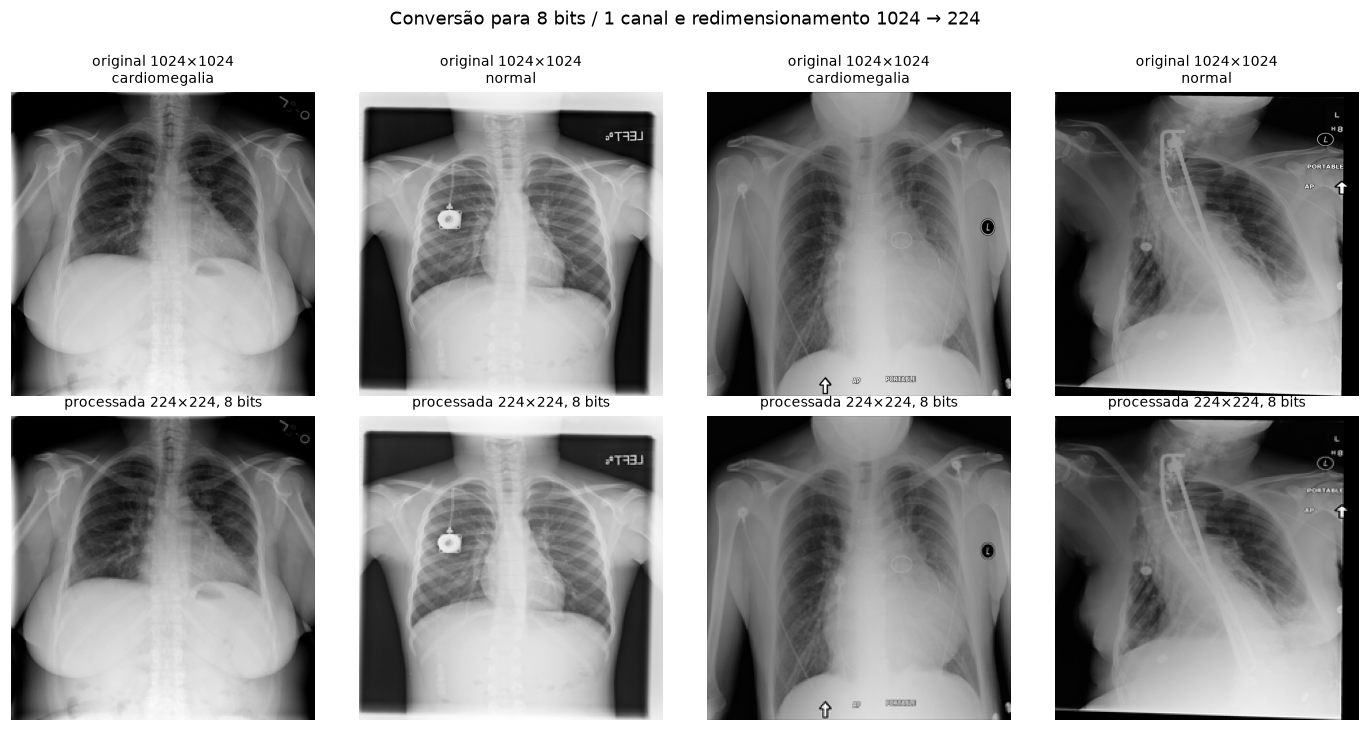

In [9]:
if exemplos_originais:
    fig, axes = plt.subplots(2, len(exemplos_originais), figsize=(3.2 * len(exemplos_originais), 6.6))
    axes = np.atleast_2d(axes).reshape(2, -1)
    for j, (nome, orig) in enumerate(exemplos_originais.items()):
        info = alvo[nome]
        proc = Image.open(OUT_DIR / info["split"] / info["rotulo"] / nome)
        axes[0, j].imshow(orig, cmap="gray"); axes[0, j].set_title(f"original {orig.size[0]}×{orig.size[1]}\n{info['rotulo']}", fontsize=9)
        axes[1, j].imshow(proc, cmap="gray"); axes[1, j].set_title(f"processada {proc.size[0]}×{proc.size[1]}, 8 bits", fontsize=9)
        for a in axes[:, j]: a.axis("off")
    plt.suptitle("Conversão para 8 bits / 1 canal e redimensionamento 1024 → 224", y=1.0)
    plt.tight_layout(); plt.savefig(FIG_DIR / "01_antes_depois.png", bbox_inches="tight"); plt.show()

## 7. Normalização

Calculamos média e desvio-padrão dos pixels **apenas no conjunto de treino** e salvamos em `normalizacao.json`. A CNN do zero usa esses valores para padronizar a entrada (z-score). A ResNet50 usa a normalização própria do ImageNet (`preprocess_input`), aplicada dentro do modelo no notebook 02.

Calcular a estatística com validação e teste juntos seria um vazamento sutil, porque o modelo "veria" informação do teste antes da avaliação.

{
  "media": 0.4986460506916046,
  "desvio": 0.25020599365234375,
  "escala": "pixel/255",
  "calculado_em": "1500 imagens do treino",
  "tamanho": 224
}


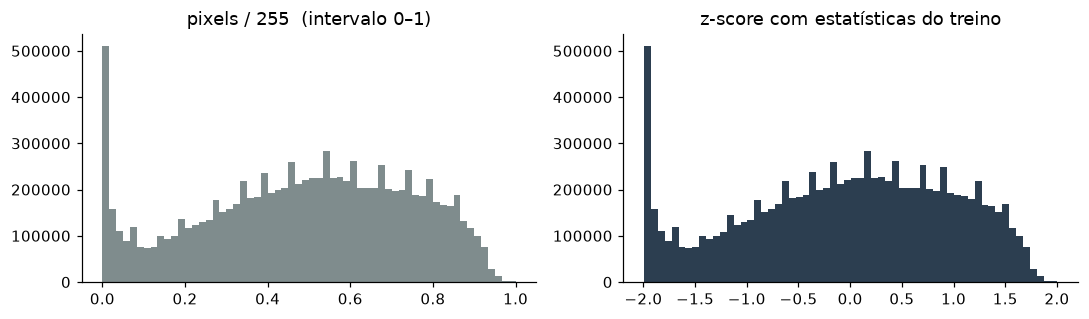

In [10]:
treino = indice[indice.split == "treino"]
amostra = treino.sample(n=min(1500, len(treino)), random_state=SEED)
pixels = np.stack([np.asarray(Image.open(OUT_DIR / c), dtype=np.float32) / 255.0 for c in amostra.caminho])
norm = {"media": float(pixels.mean()), "desvio": float(pixels.std()), "escala": "pixel/255",
        "calculado_em": f"{len(amostra)} imagens do treino", "tamanho": TAMANHO}
(OUT_DIR / "normalizacao.json").write_text(json.dumps(norm, indent=2))
print(json.dumps(norm, indent=2))

z = (pixels[:200] - norm["media"]) / norm["desvio"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(pixels[:200].ravel(), bins=60, color="#7f8c8d"); ax[0].set_title("pixels / 255  (intervalo 0–1)")
ax[1].hist(z.ravel(), bins=60, color="#2c3e50"); ax[1].set_title("z-score com estatísticas do treino")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_normalizacao.png", bbox_inches="tight"); plt.show()

## 8. Verificação do dataset final

Conferimos o balanceamento de classes em cada conjunto e a distribuição de sexo, idade e incidência. Essas variáveis são a base da análise de vieses do **Ir Além 1**.

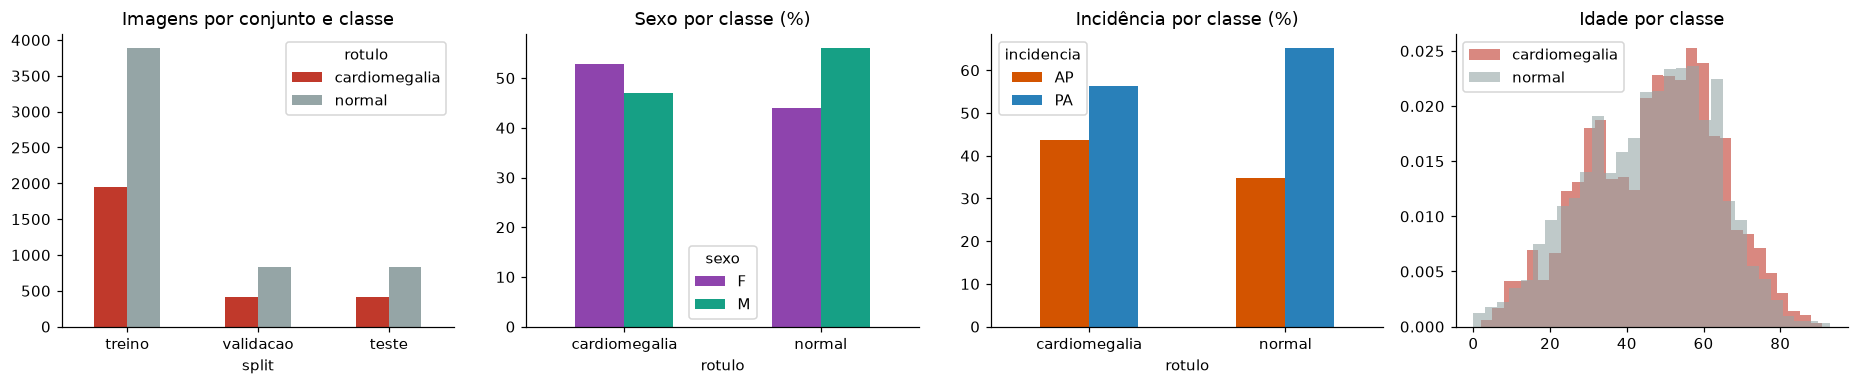

rotulo,cardiomegalia,normal,total
split,,,
treino,1943,3887,5830
validacao,417,833,1250
teste,416,832,1248
total,2776,5552,8328


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
ordem = ["treino", "validacao", "teste"]
indice.groupby(["split", "rotulo"]).size().unstack().loc[ordem].plot.bar(ax=axes[0], color=["#c0392b", "#95a5a6"], rot=0)
axes[0].set_title("Imagens por conjunto e classe")
pd.crosstab(indice.rotulo, indice.sexo, normalize="index").mul(100).plot.bar(ax=axes[1], rot=0, color=["#8e44ad", "#16a085"])
axes[1].set_title("Sexo por classe (%)")
pd.crosstab(indice.rotulo, indice.incidencia, normalize="index").mul(100).plot.bar(ax=axes[2], rot=0, color=["#d35400", "#2980b9"])
axes[2].set_title("Incidência por classe (%)")
for r, c in (("cardiomegalia", "#c0392b"), ("normal", "#95a5a6")):
    axes[3].hist(indice[indice.rotulo == r].idade, bins=30, alpha=.6, label=r, color=c, density=True)
axes[3].legend(); axes[3].set_title("Idade por classe")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_distribuicoes.png", bbox_inches="tight"); plt.show()

resumo_final = indice.groupby(["split", "rotulo"]).size().unstack().loc[ordem]
resumo_final["total"] = resumo_final.sum(axis=1)
resumo_final.loc["total"] = resumo_final.sum()
resumo_final

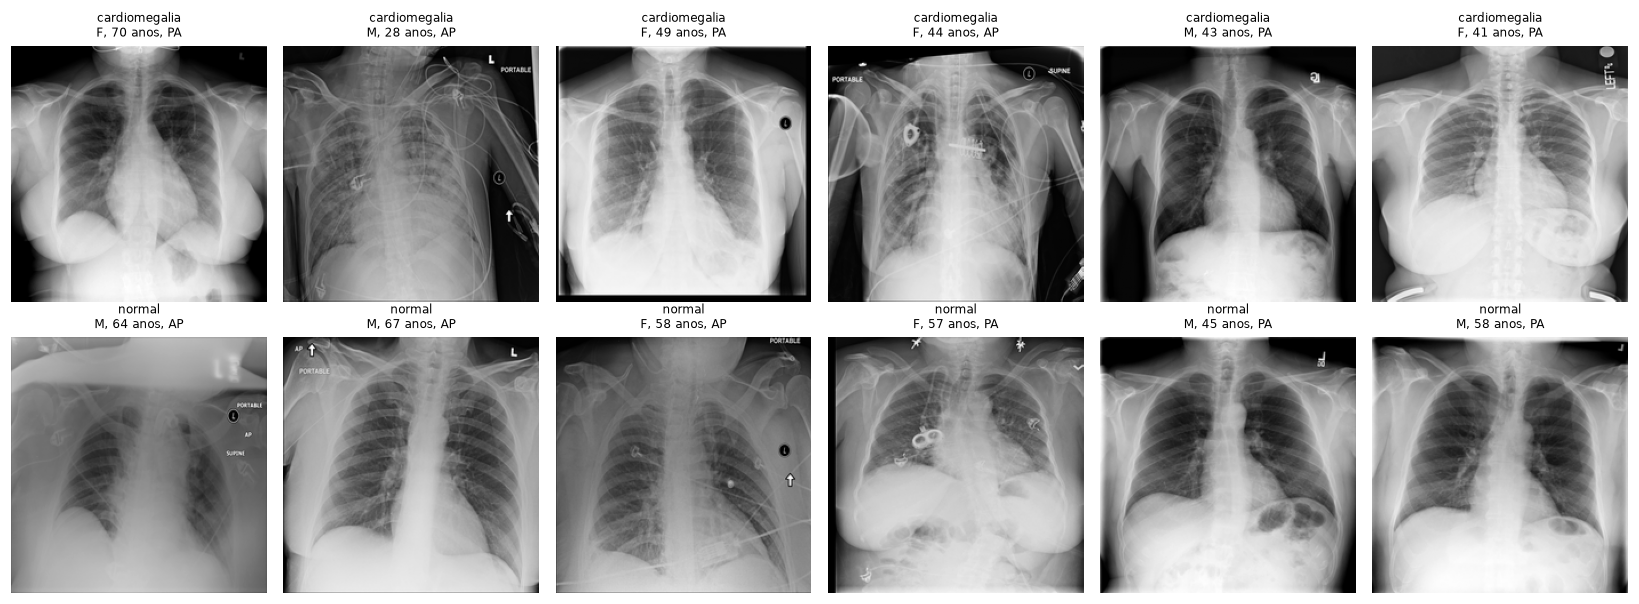

In [12]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5.6))
for linha, rot in enumerate(["cardiomegalia", "normal"]):
    ex = indice[(indice.split == "treino") & (indice.rotulo == rot)].sample(6, random_state=SEED)
    for j, r in enumerate(ex.itertuples()):
        axes[linha, j].imshow(Image.open(OUT_DIR / r.caminho), cmap="gray")
        axes[linha, j].set_title(f"{rot}\n{r.sexo}, {r.idade} anos, {r.incidencia}", fontsize=8)
        axes[linha, j].axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_amostras.png", bbox_inches="tight"); plt.show()

In [13]:
tam_mb = sum(f.stat().st_size for f in OUT_DIR.rglob("*.png")) / 1e6
print(f"Dataset processado: {len(list(OUT_DIR.rglob('*.png'))):,} PNGs · {tam_mb:.0f} MB em {OUT_DIR}")

if IN_COLAB:
    # Cópia compactada para o Drive, lida pelo notebook 02
    shutil.make_archive(str(DRIVE_DIR / "raiox_processado"), "zip", OUT_DIR)
    print("Cópia salva em", DRIVE_DIR / "raiox_processado.zip")

Dataset processado: 8,328 PNGs · 190 MB em C:\Fiap\2TIAOR-CardioIA-Fase1-Cap1\data\raiox_processado


## Resumo

* **Dataset final:** radiografias 224×224 em escala de cinza de 8 bits, organizadas em `treino/`, `validacao/` e `teste/`, cada uma com as subpastas `cardiomegalia/` e `normal/`.
* **`indice.csv`:** uma linha por imagem com split, rótulo, paciente, idade, faixa etária, sexo e incidência. É usado pelos notebooks 02 e 03.
* **`normalizacao.json`:** média e desvio do treino.
* **Sem vazamento:** os pacientes estão separados entre os conjuntos, e a normalização usa apenas o treino.

Próximo passo: `02_cnn_classificacao.ipynb`.